<a href="https://colab.research.google.com/github/BACEMA/AI-IS/blob/main/LAB1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Part 1: Security-Oriented Exploratory Data Analysis (EDA)**

**1. Exercise 1** — Data Quality Inspection & SOC Target Alignment

*   Import *PhiUSIIL_Phishing_URL_Dataset.csv* into a *pandas* DataFrame
and inspect the first 5 rows withn *df.head()*
*   Use *df.info()*, *df.isna().sum()*, *df.duplicated().sum()*, and quality, duplicates, and numerical feature scales (e.g.,
*df.describe()* to check data
URLLength , LineOfCode ,
NoOfSelfRef ).
*   Create *IsPhishing = 1 - df['label'] ( 1 = Phishing, 0 = Legitimate )* and check class proportions
using *value_counts(normalize=True)*







In [2]:
import pandas as pd

from google.colab import files
uploaded = files.upload()

Saving PhiUSIIL_Phishing_URL_Dataset.csv to PhiUSIIL_Phishing_URL_Dataset.csv


In [3]:
df = pd.read_csv("PhiUSIIL_Phishing_URL_Dataset.csv")
df.head()
df.info()
print(df.isna().sum().sum())
print(df.duplicated().sum())
print(df[["URLLength", "LineOfCode", "NoOfSelfRef"]].describe())
df["IsPhishing"] = 1 - df["label"]
print(df["IsPhishing"].value_counts(normalize=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  object 
 1   URL                         235795 non-null  object 
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  object 
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  object 
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation

**2. Exercise 2** — Class Balance, Numerical Distributions & Binary Security Indicators


*   Plot a count plot illustrating class balance (
*IsPhishing* ).
*  Plot density curves ( *sns.kdeplot* ) or boxplots comparing
legitimate and phishing URLs across: *URLLength* , *CharContinuationRate* , and
*NoOfSelfRef* .
*   Compute and plot via bar charts the percentage prevalence of binary indicators per class:
*IsHTTPS* ,
*HasPasswordField* ,
*HasCopyrightInfo* , and
*HasSocialNet*

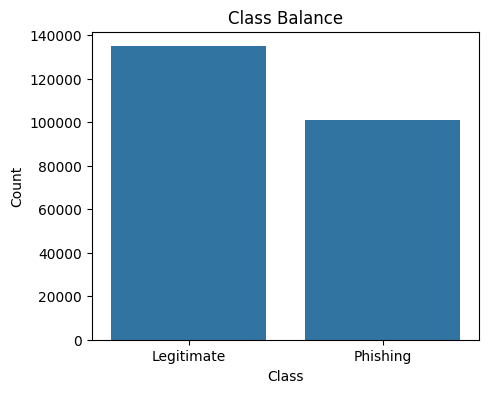

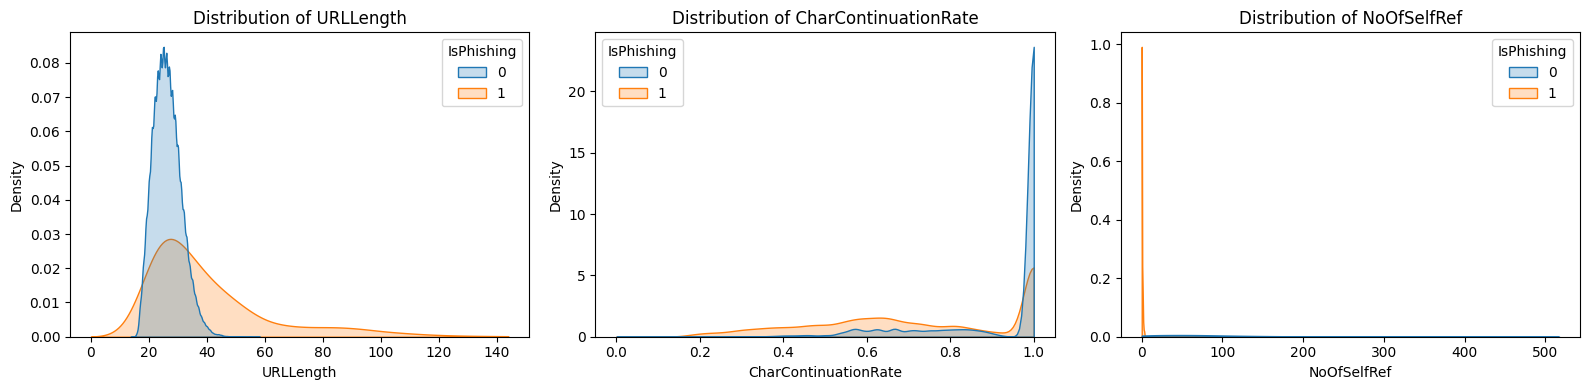

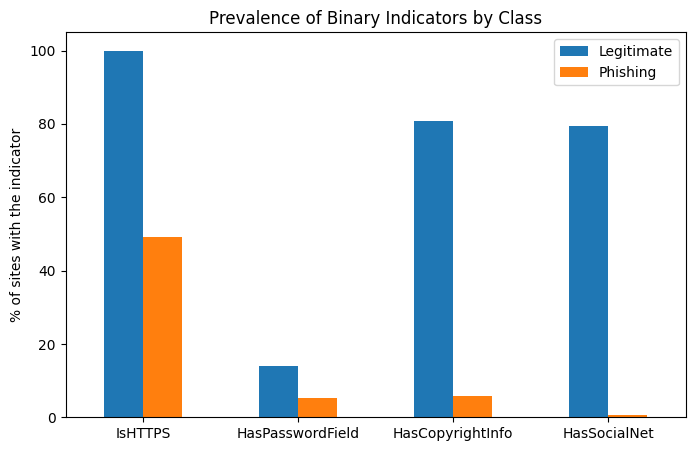

                  Legitimate  Phishing
IsHTTPS                100.0      49.2
HasPasswordField        13.8       5.4
HasCopyrightInfo        80.8       5.7
HasSocialNet            79.5       0.5


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Class balance
plt.figure(figsize=(5, 4))
sns.countplot(x="IsPhishing", data=df)
plt.xticks([0, 1], ["Legitimate", "Phishing"])
plt.xlabel("Class")
plt.ylabel("Count")
plt.title("Class Balance")
plt.show()

# 2) Numerical distributions per class (KDE)
num_cols = ["URLLength", "CharContinuationRate", "NoOfSelfRef"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.kdeplot(data=df, x=col, hue="IsPhishing", common_norm=False,
                fill=True, ax=ax, clip=(0, df[col].quantile(0.99)))
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

# 3) Prevalence (%) of binary indicators per class
bin_cols = ["IsHTTPS", "HasPasswordField", "HasCopyrightInfo", "HasSocialNet"]
prev = df.groupby("IsPhishing")[bin_cols].mean().mul(100).T
prev.columns = ["Legitimate", "Phishing"]
prev.plot(kind="bar", figsize=(8, 5))
plt.ylabel("% of sites with the indicator")
plt.title("Prevalence of Binary Indicators by Class")
plt.xticks(rotation=0)
plt.show()
print(prev.round(1))

**3. Exercise 3** — Identifier Cleanup & Feature–Target Correlations

*   Drop non-generalizable raw text columns *( FILENAME , URL , Domain , TLD , Title )*, the original
*label*  column, and the pre-computed composite score
*URLSimilarityIndex* so the model learns from true lexical
and HTML features.
*   Build your clean feature matrix
*X* and target vector
*y = df['IsPhishing']*
*   Calculate the Pearson correlation of each numerical feature in
*X* with *y* and display the Top 15 positively and
negatively correlated features in a horizontal bar plot (
*barh* )


X shape: (235795, 49)
y shape: (235795,)

=== Top 15 positively correlated features ===
SpacialCharRatioInURL         0.533537
DegitRatioInURL               0.432032
LetterRatioInURL              0.367794
NoOfOtherSpecialCharsInURL    0.358891
DomainLength                  0.283152
NoOfLettersInURL              0.258090
URLLength                     0.233445
NoOfDegitsInURL               0.177980
NoOfQMarkInURL                0.175621
TLDLength                     0.079159
NoOfEqualsInURL               0.076963
NoOfSelfRedirect              0.076463
IsDomainIP                    0.060202
HasObfuscation                0.052473
NoOfURLRedirect               0.046456
dtype: float64


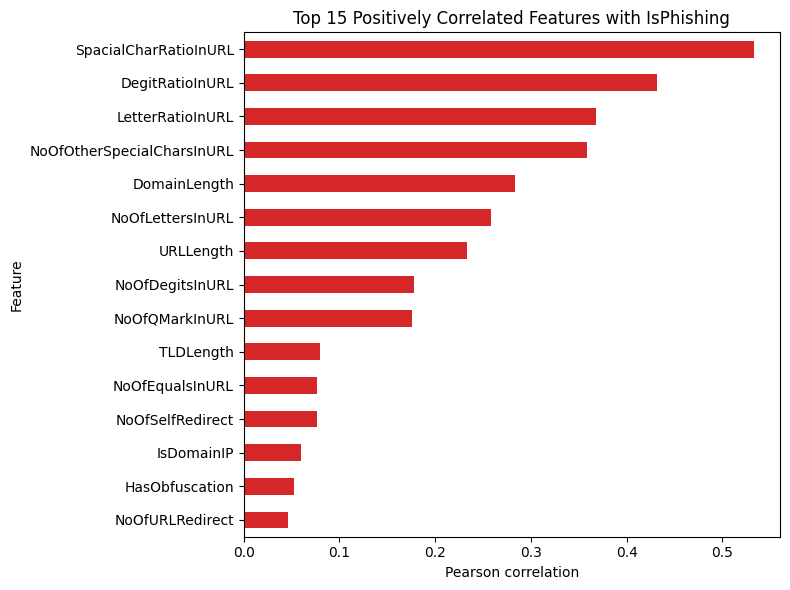


=== Top 15 negatively correlated features ===
HasSocialNet            -0.784255
HasCopyrightInfo        -0.743358
HasDescription          -0.690232
IsHTTPS                 -0.609132
DomainTitleMatchScore   -0.584905
HasSubmitButton         -0.578561
IsResponsive            -0.548608
URLTitleMatchScore      -0.539419
HasHiddenFields         -0.507731
HasFavicon              -0.493711
URLCharProb             -0.469749
CharContinuationRate    -0.467735
HasTitle                -0.459725
Robots                  -0.392620
NoOfJS                  -0.373500
dtype: float64


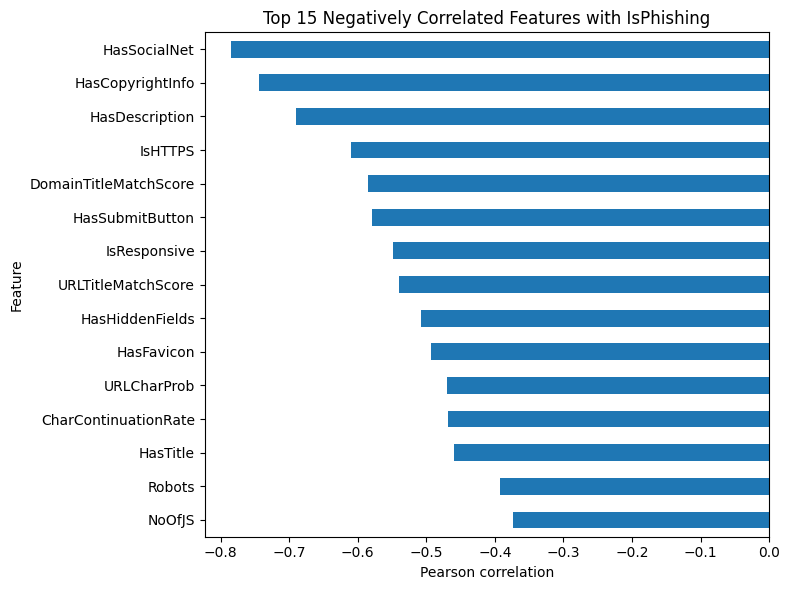

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Drop raw text identifiers, the pre-computed composite score and the labels
drop_cols = ["FILENAME", "URL", "Domain", "TLD", "Title",
             "URLSimilarityIndex", "label", "IsPhishing"]

X = df.drop(columns=drop_cols)   # clean feature matrix
y = df["IsPhishing"]             # target vector

print("X shape:", X.shape)
print("y shape:", y.shape)

# Pearson correlation of each numerical feature with the target
corr = X.corrwith(y)

top_pos = corr.sort_values(ascending=False).head(15)   # Top 15 positive
top_neg = corr.sort_values().head(15)                  # Top 15 negative

print("\n=== Top 15 positively correlated features ===")
print(top_pos)


# Plot 1: Top 15 positive correlations (associated with phishing)
plt.figure(figsize=(8, 6))
top_pos.sort_values().plot(kind="barh", color="tab:red")
plt.title("Top 15 Positively Correlated Features with IsPhishing")
plt.xlabel("Pearson correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("\n=== Top 15 negatively correlated features ===")
print(top_neg)

# Plot 2: Top 15 negative correlations (associated with legitimate sites)
plt.figure(figsize=(8, 6))
top_neg.sort_values(ascending=False).plot(kind="barh", color="tab:blue")
plt.title("Top 15 Negatively Correlated Features with IsPhishing")
plt.xlabel("Pearson correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

**Reflection Questions (Part 1):**


1. Looking at your plot for *IsHTTPS* , what percentage of phishing sites use an HTTPS certificate? Why is a static rule "*If HTTPS then Legitimate*" dangerous?

**Answer:** According to my bar plot for IsHTTPS, **49.2%** of phishing sites use an HTTPS certificate. So the presence of HTTPS is far from being a reliable sign of legitimacy.
A static rule such as *“If HTTPS then Legitimate”* is dangerous for the following reasons:

*   HTTPS proves encryption, not trustworthiness. It only guarantees that the connection between the browser and the server is encrypted and that the server owns a valid certificate for its domain. It says nothing about the intentions of the site owner.
*  Certificates are free and easy to obtain. Certificate authorities such as Let’s Encrypt issue certificates automatically to anyone, including attackers. A phishing page can therefore get the padlock in a few minutes.
*   The rule would create many false negatives. With 49.2% of phishing sites using HTTPS, this rule would classify nearly half of the attacks as legitimate and let them pass through the SOC without any alert. In a security context, a missed attack (low Recall) is the most costly error.
*   Attackers would adapt immediately. Once the rule is known, attackers would simply add HTTPS to all their pages, and users would get a false sense of security.

2.   Why do phishing websites typically have very few internal links ( *NoOfSelfRef* ) but frequently contain a password field ( *HasPasswordField* )?

**Answer:**
A phishing site is usually a **single cloned page**, typically a fake login form copied from a bank or a service. It has no real navigation, so it contains very few links pointing to its own domain. A legitimate site has menus, sub-pages, and a full internal structure, so it has many self-references.
The password field is **the goal of the attack**: the attacker wants to harvest credentials. The login form is therefore the core of the page, so HasPasswordField is frequent among phishing sites.
Together these two features describe the same profile: a page that is poor in structure but focused on capturing sensitive data.

3.   What would happen in production if we left raw string identifiers like *FILENAME* , *URL* , or *Domain* in our training matrix?

**Answer:**
If we left raw string identifiers such as FILENAME, URL, or Title in the training matrix, the model would not learn what really makes a website malicious. These columns are almost unique for every row, so the model would simply memorize that a given exact string corresponds to phishing instead of learning general patterns. This is classic **overfitting**: the test scores would look excellent, but in production the performance would collapse, because almost all real traffic consists of URLs the model has never seen before. These raw strings can also carry collection artifacts, such as naming conventions or source-specific patterns, that happen to be correlated with the label. The model would exploit them, which is a form of **data leakage**, and it would give an over-optimistic evaluation that does not reflect its real detection ability. Finally, encoding thousands of unique strings would create a huge and sparse feature space, which makes training slow and unstable.

**Part 2: Zero-Data Leakage Preprocessing & Standardization**

**4. Exercise 4** — Stratified 75/25 Split & Training-Only Standardization

*   Split *X* and *y* into a training set (75%) and a test set (25%) using *train_test_split(X, y, test_size=0.25, stratify=y,random_state=42)*.
*   Instantiate *StandardScaler()* from *scikit-learn.*

*   Fit and transform only the training set via *scaler.fit_transform(X_train)*, then transform the test set via *scaler.transform(X_test)* (never call *.fit()* on the test set!).
*   Retain column names and indices in DataFrames *X_train_scaled* and *X_test_scaled* to facilitate weight and SHAP interpretation.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Stratified 75/25 split (same class proportions in train and test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

# 2. Instantiate the scaler
scaler = StandardScaler()

# 3. Fit on TRAIN only, then transform both sets
X_train_scaled = scaler.fit_transform(X_train)   # learns mean/std from train only
X_test_scaled = scaler.transform(X_test)         # applies train mean/std (no .fit() here!)

# 4. Keep column names and indices (DataFrames) for weight / SHAP interpretation
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)
print('Train shape:', X_train_scaled.shape, '| Test shape:', X_test_scaled.shape)
print('Phishing ratio -> train: %.4f | test: %.4f' % (y_train.mean(), y_test.mean()))

# Scale before standardization (for the reflection question)
print(X_train[['LineOfCode', 'IsHTTPS']].describe().T[['min', 'max', 'mean', 'std']])

# After standardization: train mean ~ 0 and std ~ 1 (test is only approximately so)
print('Train mean (max abs):', round(X_train_scaled.mean().abs().max(), 6))
print('Train std (mean):', round(X_train_scaled.std().mean(), 4))
print('Test mean (max abs):', round(X_test_scaled.mean().abs().max(), 4))

Train shape: (176846, 49) | Test shape: (58949, 49)
Phishing ratio -> train: 0.4281 | test: 0.4281
            min       max         mean          std
LineOfCode  2.0  442666.0  1148.751400  3642.388543
IsHTTPS     0.0       1.0     0.782483     0.412558
Train mean (max abs): 0.0
Train std (mean): 1.0
Test mean (max abs): 0.0079


**Reflection Questions (Part 2):**

1.   Compare the scale of *LineOfCode* (values up to 10,000+) and *IsHTTPS* (0 or 1) before standardization. Why would L1/L2 regularization be skewed without *StandardScaler*?

**Answer:** Before standardization, LineOfCode reaches 442,666 in my dataset while IsHTTPS is only 0 or 1, so their scales differ by several orders of magnitude. L1/L2 regularization penalizes the size of the coefficients without taking the scale of the features into account. A large-scale feature like LineOfCode needs only a tiny coefficient, so it is barely penalized and tends to dominate. A small-scale feature like IsHTTPS needs a large coefficient to have the same influence, so it is over-penalized even if it is informative. Without StandardScaler, the model therefore keeps or discards features according to their units of measurement rather than their predictive power. After standardization, all features have mean 0 and standard deviation 1, so the penalty is fair and the coefficients are comparable.

2.   Precisely explain why calling *scaler.fit_transform(X)* before
*train_test_split* constitutes Preprocessing Data Leakage.

**Answer:** Calling scaler.fit_transform(X) before the split computes the mean and standard deviation using all rows, including those that will become the test set. Information from the test data therefore leaks into the preprocessing of the training data, and the test set is no longer truly “unseen”. This makes the test set look more similar to the training set than real future data would, so the Precision, Recall and F1 scores become over-optimistic. In production, new URLs can only be scaled with the statistics learned during training, so the real performance would be lower than reported. The correct way is to split first, use fit_transform on X_train only, and then apply transform to X_test.

**Part 3: Training & Interpreting Parameterized Logistic Regression**

**5. Exercise 5** — Experimental Comparison of the 5 Configurations


*   Train the 5 models from the table above on *X_train_scaled* and evaluate them on *X_test_scaled* at default threshold $\tau = 0.50$.
*   For each model, record in a summary DataFrame: Precision, Recall (TPR), F1-Score, PR-AUC
(*average_precision_score*), False Positives (FP), False Negatives (FN), and Zeroed Weights (Sparsity) ($\vert{}w_j\vert{} < 10^{-4}$)

In [7]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix)

# Model configurations (M1 to M5)
configs = {
    "M1: Unregularized": LogisticRegression(penalty=None, solver="lbfgs",
                                            max_iter=500, random_state=42),
    "M2: Strong L2 (C=0.001)": LogisticRegression(penalty="l2", C=0.001, solver="lbfgs",
                                                  max_iter=500, random_state=42),
    "M3: Standard L2 (C=1.0)": LogisticRegression(penalty="l2", C=1.0, solver="lbfgs",
                                                  max_iter=500, random_state=42),
    "M4: Sparse L1 (C=0.01)": LogisticRegression(penalty="l1", C=0.01, solver="liblinear",
                                                 max_iter=500, random_state=42),
    "M5: SOC Weighted (balanced)": LogisticRegression(penalty="l2", C=1.0,
                                                      class_weight="balanced",
                                                      solver="lbfgs", max_iter=500,
                                                      random_state=42),
}

threshold = 0.50
results = []
trained_models = {}   # kept for the next exercises (weights, odds ratios)

for name, model in configs.items():
    # Train on the scaled training set
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model

    # Predicted probabilities of the positive class (Phishing) and labels at tau = 0.50
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)

    # Confusion matrix: [[TN, FP], [FN, TP]]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    # Sparsity: number of weights with |w_j| < 1e-4
    zeroed = int((np.abs(model.coef_[0]) < 1e-4).sum())

    results.append({
        "Model": name,
        "Precision": precision_score(y_test, y_pred),
        "Recall (TPR)": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "PR-AUC": average_precision_score(y_test, y_proba),
        "FP": fp,
        "FN": fn,
        "Zeroed Weights": zeroed,
    })

summary_df = pd.DataFrame(results).set_index("Model")
display(summary_df.round(4))

,Precision,Recall (TPR),F1-Score,PR-AUC,FP,FN,Zeroed Weights
Model,,,,,,,
M1: Unregularized,0.9996,0.9990,0.9993,1.0,11,25,0
M2: Strong L2 (C=0.001),0.9985,0.9958,0.9971,1.0,39,105,0
M3: Standard L2 (C=1.0),0.9996,0.9989,0.9992,1.0,10,28,0
M4: Sparse L1 (C=0.01),0.9993,0.9971,0.9982,1.0,18,72,24
M5: SOC Weighted (balanced),0.9995,0.9990,0.9992,1.0,13,25,0


**6. Exercise 6** — L1 Regularization Path (Feature Selection)


*  Vary *C* in *[0.002, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]* with *penalty='l1'* and *solver='liblinear'*, and plot the number of retained active features ($\vert{}w_j\vert{} \ge 10^{-4}$) as a function of *C* (on a log scale).

,C,Active_Features,Zeroed_Features
0,0.002,22,27
1,0.010,30,19
2,0.050,45,4
3,0.100,47,2
4,0.500,48,1
5,1.000,49,0
6,5.000,49,0


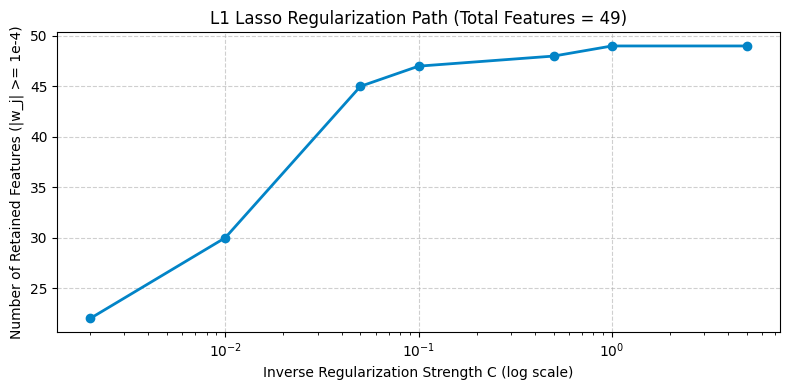

In [8]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

C_values = [0.002, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]
active_features_count = []

for c_val in C_values:
    m_l1 = LogisticRegression(penalty='l1', C=c_val, solver='liblinear',
                              tol=1e-2, max_iter=100, random_state=42)
    m_l1.fit(X_train_scaled, y_train)
    n_active = int(np.sum(np.abs(m_l1.coef_[0]) >= 1e-4))
    active_features_count.append(n_active)

path_df = pd.DataFrame({"C": C_values,
                        "Active_Features": active_features_count,
                        "Zeroed_Features": [X.shape[1] - k for k in active_features_count]})
display(path_df)

plt.figure(figsize=(8, 4))
plt.plot(C_values, active_features_count, marker='o', linewidth=2, color='#0284c7')
plt.xscale('log')
plt.xlabel("Inverse Regularization Strength C (log scale)")
plt.ylabel("Number of Retained Features (|w_j| >= 1e-4)")
plt.title(f"L1 Lasso Regularization Path (Total Features = {X.shape[1]})")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**7. Exercise 7** — Interpreting Log-Odds ($w_j$) and Odds Ratios ($e^{w_j}$)


*   Extract coefficients *model_l2.coef_[0]* from your standard L2 model (M3), compute the Odds Ratio *np.exp(w)* for each feature, and include the corresponding sparse weight from M4 (*L1_Sparse_Weight*).
*   Display the Top 8 features with positive weights ($w_j > 0$, increasing phishing risk) and Top 8 with
negative weights ($w_j < 0$, indicating legitimate sites).





In [9]:
import numpy as np
import pandas as pd

# Retrieve M3 (standard L2) and M4 (sparse L1) from Exercise 5
model_l2 = trained_models["M3: Standard L2 (C=1.0)"]
model_l1 = trained_models["M4: Sparse L1 (C=0.01)"]

# Coefficients (log-odds) and Odds Ratios
w = model_l2.coef_[0]
coef_df = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "Weight_w (M3 L2)": w,
    "Odds_Ratio exp(w)": np.exp(w),
    "L1_Sparse_Weight (M4)": model_l1.coef_[0],
})

# Top 8 positive weights (increase phishing risk)
top_pos = (coef_df[coef_df["Weight_w (M3 L2)"] > 0]
           .sort_values("Weight_w (M3 L2)", ascending=False)
           .head(8))

# Top 8 negative weights (indicate legitimate sites)
top_neg = (coef_df[coef_df["Weight_w (M3 L2)"] < 0]
           .sort_values("Weight_w (M3 L2)", ascending=True)
           .head(8))

print("=== Top 8 features with POSITIVE weights (increase phishing risk) ===")
display(top_pos.round(4).reset_index(drop=True))

print("\n=== Top 8 features with NEGATIVE weights (indicate legitimate sites) ===")
display(top_neg.round(4).reset_index(drop=True))

=== Top 8 features with POSITIVE weights (increase phishing risk) ===


,Feature,Weight_w (M3 L2),Odds_Ratio exp(w),L1_Sparse_Weight (M4)
0,LetterRatioInURL,4.7228,112.4883,2.1726
1,DegitRatioInURL,3.6057,36.8079,1.8036
2,SpacialCharRatioInURL,3.5981,36.5306,1.9106
3,LargestLineLength,2.5575,12.9038,0.0848
4,NoOfOtherSpecialCharsInURL,2.0834,8.0315,0.0000
5,NoOfLettersInURL,1.6801,5.3660,0.0000
6,CharContinuationRate,1.4202,4.1378,0.0000
7,NoOfDegitsInURL,0.9718,2.6426,0.0000



=== Top 8 features with NEGATIVE weights (indicate legitimate sites) ===


,Feature,Weight_w (M3 L2),Odds_Ratio exp(w),L1_Sparse_Weight (M4)
0,IsHTTPS,-6.9024,0.0010,-3.5777
1,NoOfJS,-3.6536,0.0259,-1.2017
2,NoOfSelfRef,-3.1249,0.0439,-0.8227
3,NoOfImage,-2.7981,0.0609,-0.1505
4,NoOfExternalRef,-2.6414,0.0713,-0.0157
5,LineOfCode,-2.3676,0.0937,0.0000
6,HasSocialNet,-2.1533,0.1161,-1.0887
7,DomainLength,-1.9117,0.1478,-0.0585


**Reflection Questions (Part 3):**

1.   How many variables did M4: Sparse L1 Lasso (C=0.01) eliminate? Did the F1-Score or PR-AUC drop significantly? What is the advantage for a real-time firewall?

**Answer:** M4 (L1, C = 0.01) set 24 of the 49 weights to zero, keeping only 25 active features, so it eliminated about 49% of the variables. Compared with M3, the F1-Score went from 0.9992 to 0.9982 (a drop of only 0.0010) and the PR-AUC stayed at 1.0 (rounded to 4 decimals), so the drop is not significant. Precision moved from 0.9996 to 0.9993 and Recall from 0.9989 to 0.9971. The cost is visible only in the raw error counts: False Negatives rose from 28 to 72 and False Positives from 10 to 18, which is still a tiny fraction of the test set. This shows that about half of the features are redundant. For a real-time firewall this is a major advantage: fewer features means less URL/HTML parsing and feature extraction per request, lower latency and memory use, and a simpler, more interpretable and auditable model that only needs to compute the 25 retained features.

2.   What is the impact of class_weight='balanced' (M5) on False Positives and False Negatives compared to
M3?

**Answer:** Compared with M3, M5 reduced the False Negatives from 28 to 25 and increased the False Positives from 10 to 13. The Recall went from 0.9989 to 0.9990 while the Precision went from 0.9996 to 0.9995. This is the expected direction: with class_weight='balanced', errors on the phishing class are weighted more heavily in the loss, which shifts the decision boundary toward catching more attacks, at the cost of a few more false alarms. In a SOC, a missed phishing site (FN) is usually more costly than a false alert (FP), so M5 is slightly preferable. However, the effect is very small here because the classes are only moderately imbalanced (about 43% / 57%) and all models already perform near-perfectly, so the difference (3 fewer FN for 3 more FP) is marginal.

3.   How do you interpret a positive weight $w_j > 0$ ($e^{w_j} > 1$) versus a negative weight $w_j < 0$
($e^{w_j} < 1$) in $\sigma(\mathbf{w}^\top\mathbf{x} + b)$?

**Answer:** In σ(wᵀx + b), the term wᵀx + b is the log-odds of phishing. A positive weight (w_j > 0, e^{w_j} > 1) increases the odds of phishing: when feature j increases by one standard deviation, the odds are multiplied by e^{w_j}, so the sigmoid output moves toward 1 (phishing). A negative weight (w_j < 0, e^{w_j} < 1) decreases the odds of phishing: they are multiplied by a factor below 1, so the output moves toward 0 (legitimate site).






**Part 4: Model Explainability (SHAP) & SOC Threshold Analysis**

**8. Exercise 8** — Global SHAP Explanations ( shap.LinearExplainer )

*   Initialize the SHAP explainer on M3 using the training distribution: *explainer = shap.LinearExplainer(model_l2, X_train_scaled)* .
*   Calculate SHAP values on a sample of 1,000 test URLs:
*shap_values = explainer(X_test_scaled.iloc[:1000])*.
*   Display the global bar plot
*shap.plots.bar(shap_values, max_display=15*) (mean $|\phi_j|$) and the
beeswarm plot
*shap.plots.beeswarm(shap_values, max_display=15)*.

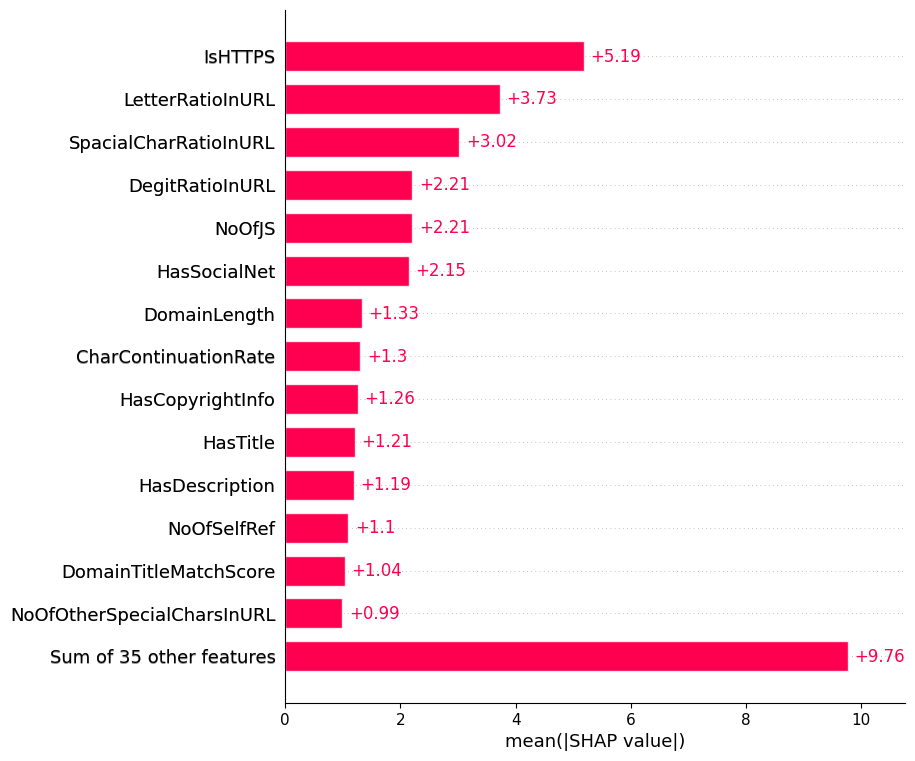

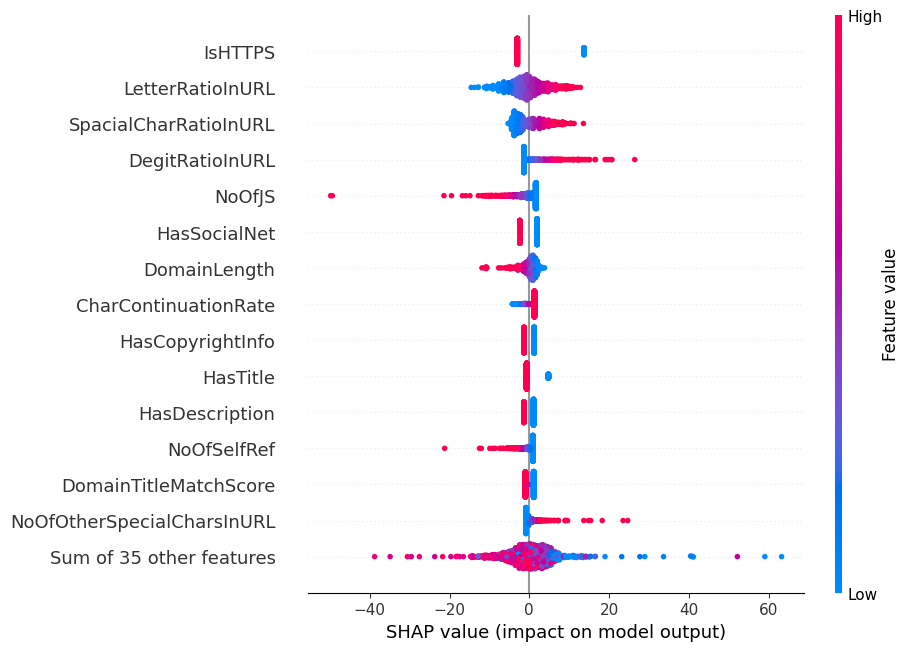

In [10]:
import shap
import matplotlib.pyplot as plt

# Retrieve M3 (standard L2) from Exercise 5
model_l2 = trained_models["M3: Standard L2 (C=1.0)"]

# Initialize the explainer using the training distribution as background
explainer = shap.LinearExplainer(model_l2, X_train_scaled)

# SHAP values on a sample of 1,000 test URLs
X_sample = X_test_scaled.iloc[:1000]
shap_values = explainer(X_sample)

# Global bar plot: mean |SHAP value| per feature (Top 15)
shap.plots.bar(shap_values, max_display=15)

# Beeswarm plot: distribution and direction of each feature's impact (Top 15)
shap.plots.beeswarm(shap_values, max_display=15)

**9. Exercise 9** — Local SOC Alert Triage (TP, TN, and FP Waterfall Plots)

*   Within your 1,000-URL test sample, identify the index of a True Positive (TP), a True Negative (TN), and
a False Positive (FP — false alarm).
*   For each of the 3 cases, plot
*shap.plots.waterfall (shap_values[idx], max_display=10*) (passing
unscaled feature values for readability) to inspect how $\phi_0 + \sum \phi_j(x)$ transitions from $E[f(X)]$
to $f(x)$.

In the 1,000-URL sample -> TP: 421 | TN: 579 | FP: 0

TP: sample index 2, P(Phishing) = 0.9999


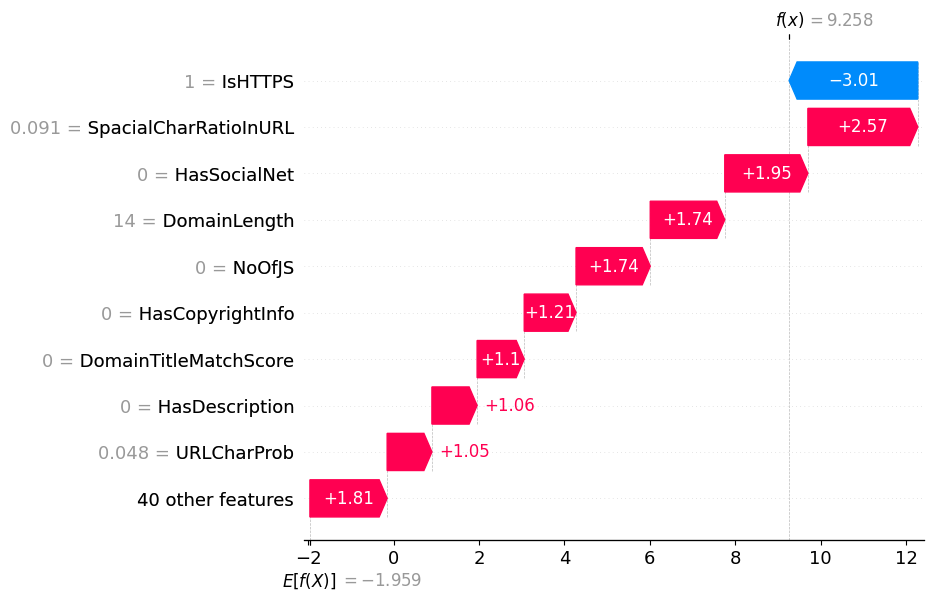


TN: sample index 0, P(Phishing) = 0.0000


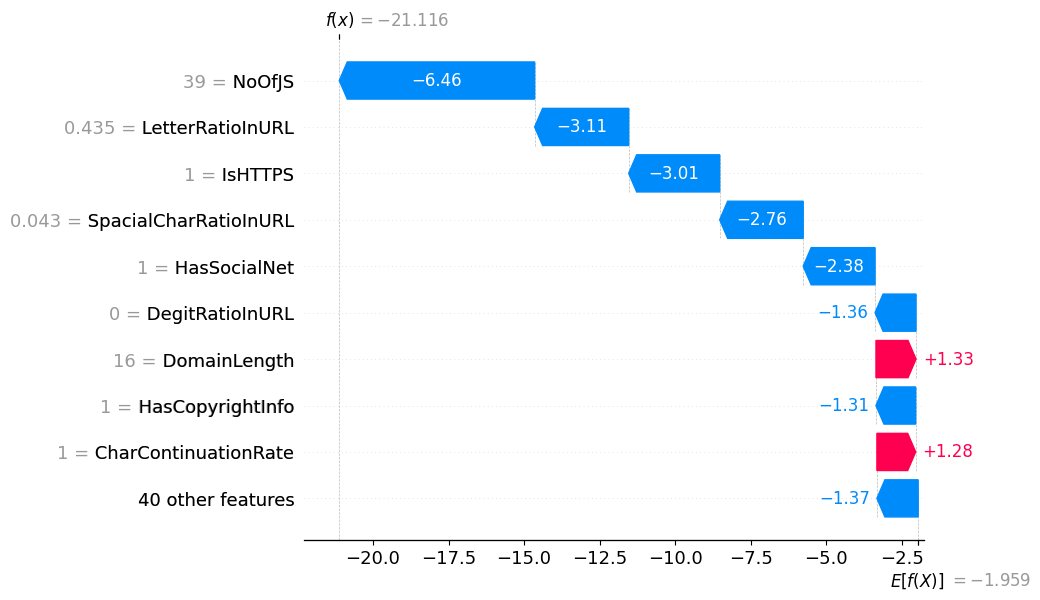


No FP in the 1,000-URL sample. Using a FP from the full test set: position 3590, P(Phishing) = 0.6149


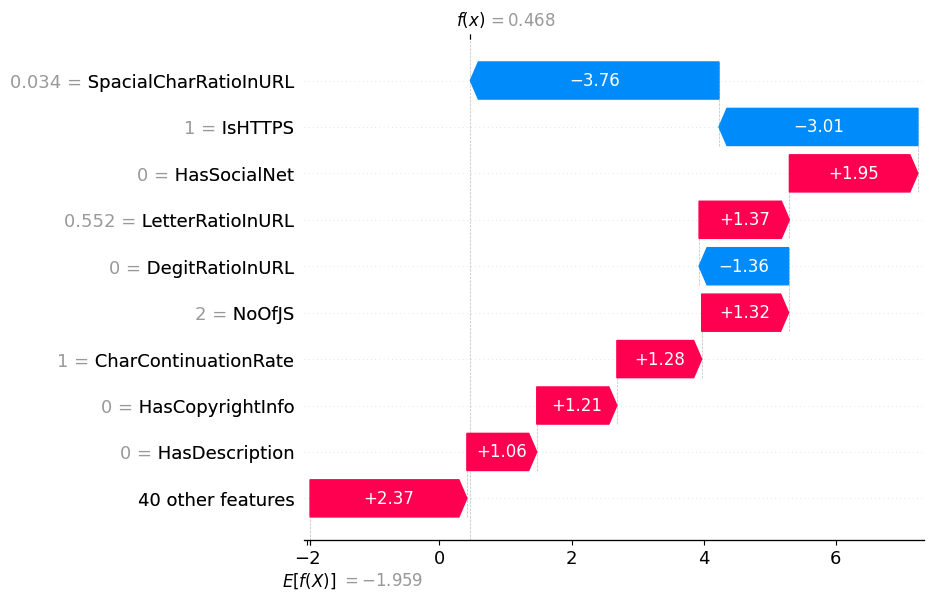

In [11]:
# Test sample (same 1,000 URLs as Exercise 8): scaled for the model, unscaled for display
X_sample_scaled = X_test_scaled.iloc[:1000]
X_sample_raw = X_test.iloc[:1000]
y_sample = y_test.iloc[:1000].values

# Predictions of M3 at threshold tau = 0.50
proba = model_l2.predict_proba(X_sample_scaled)[:, 1]
pred = (proba >= 0.50).astype(int)

# Indices (within the sample) of TP, TN and FP
tp_idx = np.where((y_sample == 1) & (pred == 1))[0]
tn_idx = np.where((y_sample == 0) & (pred == 0))[0]
fp_idx = np.where((y_sample == 0) & (pred == 1))[0]
print(f"In the 1,000-URL sample -> TP: {len(tp_idx)} | TN: {len(tn_idx)} | FP: {len(fp_idx)}")

# SHAP explanation with UNSCALED feature values (for readability)
shap_raw = shap.Explanation(values=shap_values.values,
                            base_values=shap_values.base_values,
                            data=X_sample_raw.values,
                            feature_names=list(X_sample_raw.columns))

# Case 1: True Positive (phishing correctly detected)
i_tp = tp_idx[0]
print(f"\nTP: sample index {i_tp}, P(Phishing) = {proba[i_tp]:.4f}")
shap.plots.waterfall(shap_raw[i_tp], max_display=10)

# Case 2: True Negative (legitimate site correctly allowed)
i_tn = tn_idx[0]
print(f"\nTN: sample index {i_tn}, P(Phishing) = {proba[i_tn]:.4f}")
shap.plots.waterfall(shap_raw[i_tn], max_display=10)

# Case 3: False Positive (legitimate site wrongly flagged as phishing)
if len(fp_idx) > 0:
    i_fp = fp_idx[0]
    print(f"\nFP: sample index {i_fp}, P(Phishing) = {proba[i_fp]:.4f}")
    shap.plots.waterfall(shap_raw[i_fp], max_display=10)
else:
    # No FP in the first 1,000 URLs: search the full test set instead
    proba_full = model_l2.predict_proba(X_test_scaled)[:, 1]
    fp_full = np.where((y_test.values == 0) & (proba_full >= 0.50))[0]
    j = fp_full[0]
    print(f"\nNo FP in the 1,000-URL sample. Using a FP from the full test set: "
          f"position {j}, P(Phishing) = {proba_full[j]:.4f}")
    sv_fp = explainer(X_test_scaled.iloc[[j]])
    fp_raw = shap.Explanation(values=sv_fp.values[0],
                              base_values=sv_fp.base_values[0],
                              data=X_test.iloc[j].values,
                              feature_names=list(X_test.columns))
    shap.plots.waterfall(fp_raw, max_display=10)

**10. Exercise 10** — Operational Decision Threshold Tuning ($\tau$)

*   Using predicted probabilities from M3 on the full test set, compare confusion matrices (TP, TN, FP, FN),
Precision, Recall, and F1-Score across three operational thresholds: $\tau = 0.20$ (Threat Hunting mode),
$\tau = 0.50$ (Default mode), and $\tau = 0.85$ (Automated Firewall Blocking mode).

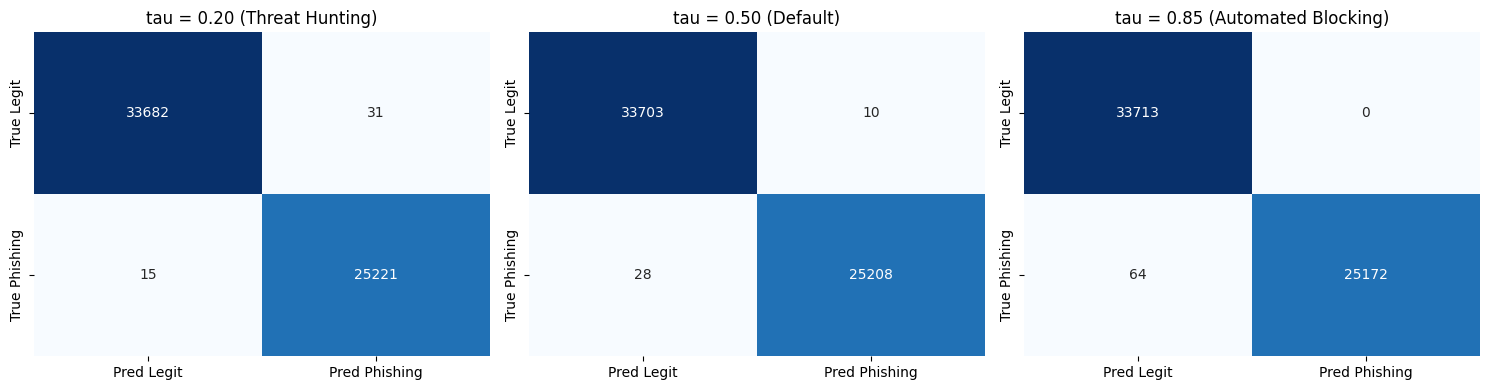

,TP,TN,FP,FN,Precision,Recall,F1-Score
Mode,,,,,,,
tau = 0.20 (Threat Hunting),25221,33682,31,15,0.9988,0.9994,0.9991
tau = 0.50 (Default),25208,33703,10,28,0.9996,0.9989,0.9992
tau = 0.85 (Automated Blocking),25172,33713,0,64,1.0000,0.9975,0.9987


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (confusion_matrix, precision_score,
                             recall_score, f1_score)

# Predicted probabilities of Phishing from M3 on the FULL test set
model_l2 = trained_models["M3: Standard L2 (C=1.0)"]
y_proba = model_l2.predict_proba(X_test_scaled)[:, 1]

# Operational thresholds
thresholds = {
    "tau = 0.20 (Threat Hunting)": 0.20,
    "tau = 0.50 (Default)": 0.50,
    "tau = 0.85 (Automated Blocking)": 0.85,
}

rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, tau) in zip(axes, thresholds.items()):
    y_pred = (y_proba >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    rows.append({
        "Mode": name,
        "TP": tp, "TN": tn, "FP": fp, "FN": fn,
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
    })

    # Confusion matrix heatmap for each threshold
    sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt="d", cmap="Blues",
                cbar=False, ax=ax,
                xticklabels=["Pred Legit", "Pred Phishing"],
                yticklabels=["True Legit", "True Phishing"])
    ax.set_title(name)

plt.tight_layout()
plt.show()

threshold_df = pd.DataFrame(rows).set_index("Mode")
display(threshold_df.round(4))

**Reflection Questions (Part 4):**


1.   What is the mathematical difference between inspecting a global weight $w_j$ and looking at a local SHAP value $\phi_j(x)$ for a specific URL?

**Answer:** A global weight w_j is a fixed parameter of the model: it is the same for every URL and tells how much the log-odds of phishing change when feature j increases by one standard deviation. A local SHAP value φ_j(x) is specific to one URL. For a linear model it equals w_j · (x_j − E[x_j]), so it combines the global weight with how far this URL’s value is from the average training value. A feature with a large weight contributes almost nothing if the URL has an average value, while a feature with a small weight can contribute a lot if the value is extreme. The values φ_j(x) add up to the base value E[f(X)] to give exactly the log-odds f(x) of that URL. The weight explains the model globally, whereas the SHAP value explains one individual alert.

2.   On your False Positive (FP) Waterfall plot, which 2 or 3 features misled the model and caused this false alarm?

**Answer:** The legitimate site (P(Phishing) = 0.6149) was flagged mainly because of HasSocialNet = 0 (+1.95), LetterRatioInURL = 0.552 (+1.37) and NoOfJS = 2 (+1.32). The absence of social network links and the low number of JavaScript files are typical phishing signals, and the high letter ratio in the URL also pushed toward phishing. The IsHTTPS = 1 (−3.01) and low special-character ratio (−3.76) pushed toward legitimate but were not enough to compensate, so the total crossed the 0.50 threshold.

3.   Why would a SOC deploy $\tau = 0.85$ for automated DNS/firewall blocking while routing URLs with $0.20 \le
P(\text{Phishing}) < 0.85$ to a human analyst queue?

**Answer:** Automatic blocking acts without review, so a False Positive blocks a legitimate site. At τ = 0.85 my results show 0 FP and a Precision of 1.0000, so no legitimate site is blocked automatically. The cost is a lower Recall (0.9975, 64 FN instead of 15 at τ = 0.20). To catch these missed attacks, URLs with 0.20 ≤ P < 0.85 (about 80 URLs out of 58,949) are sent to a human analyst, who uses the SHAP explanation to decide. This combines the safety of automation for clear cases with human judgment for ambiguous ones, while keeping the alert volume manageable.







